In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import warnings
warnings.filterwarnings("ignore")

from google.colab.output import eval_js

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("mit805-project")
         .config("spark.driver.memory", "6g")
         .getOrCreate())
spark

print(f"Spark Session Active: {spark.version}")

Spark Session Active: 4.0.4


In [2]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(4040)").rstrip("/") + "/jobs/")

https://4040-m-s-kkb-usw1b1-c2a9s26vb6n3-b.us-west1-1.prod.colab.dev/jobs/


#Part 1 – Data Collection & Analysis

## Download Data

In [3]:
os.makedirs("/content/data/raw", exist_ok=True)

months = [
    "2024-01", "2024-02", "2024-03", "2024-04", "2024-05", "2024-06",
    "2024-07", "2024-08", "2024-09", "2024-10", "2024-11", "2024-12",
    "2025-01", "2025-02", "2025-03", "2025-04", "2025-05", "2025-06",
    "2025-07", "2025-08", "2025-09", "2025-10", "2025-11", "2025-12",
    "2026-01", "2026-02", "2026-03",
]

base_url = "https://d37ci6vzurychx.cloudfront.net/trip-data/"

for m in months:
    file_name = f"fhvhv_tripdata_{m}.parquet"
    file_path = "/content/data/raw/" + file_name
    if not os.path.exists(file_path):
        print("Downloading", file_name)
        urllib.request.urlretrieve(base_url + file_name, file_path + ".part")
        os.rename(file_path + ".part", file_path)

zone_path = "/content/data/taxi_zone_lookup.csv"
if not os.path.exists(zone_path):
    urllib.request.urlretrieve("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv", zone_path)

##Validate Downloaded Data

In [4]:
def folder_size_gb(folder):
    total = 0
    for root, dirs, files in os.walk(folder):
        for f in files:
            total += os.path.getsize(os.path.join(root, f))
    return total / 1e9

for f in sorted(os.listdir("/content/data/raw")):
    size_mb = os.path.getsize("/content/data/raw/" + f) / 1e6
    print(f"{f}: {size_mb:.0f} MB")

print(f"Working dataset: {folder_size_gb('/content/data/raw'):.2f} GB")

fhvhv_tripdata_2024-01.parquet: 473 MB
fhvhv_tripdata_2024-02.parquet: 462 MB
fhvhv_tripdata_2024-03.parquet: 508 MB
fhvhv_tripdata_2024-04.parquet: 476 MB
fhvhv_tripdata_2024-05.parquet: 499 MB
fhvhv_tripdata_2024-06.parquet: 484 MB
fhvhv_tripdata_2024-07.parquet: 468 MB
fhvhv_tripdata_2024-08.parquet: 466 MB
fhvhv_tripdata_2024-09.parquet: 466 MB
fhvhv_tripdata_2024-10.parquet: 485 MB
fhvhv_tripdata_2024-11.parquet: 480 MB
fhvhv_tripdata_2024-12.parquet: 508 MB
fhvhv_tripdata_2025-01.parquet: 491 MB
fhvhv_tripdata_2025-02.parquet: 462 MB
fhvhv_tripdata_2025-03.parquet: 502 MB
fhvhv_tripdata_2025-04.parquet: 487 MB
fhvhv_tripdata_2025-05.parquet: 517 MB
fhvhv_tripdata_2025-06.parquet: 491 MB
fhvhv_tripdata_2025-07.parquet: 487 MB
fhvhv_tripdata_2025-08.parquet: 480 MB
fhvhv_tripdata_2025-09.parquet: 481 MB
fhvhv_tripdata_2025-10.parquet: 518 MB
fhvhv_tripdata_2025-11.parquet: 507 MB
fhvhv_tripdata_2025-12.parquet: 536 MB
fhvhv_tripdata_2026-01.parquet: 506 MB
fhvhv_tripdata_2026-02.pa

##Load Data

In [5]:
df = spark.read.option("mergeSchema", "true").parquet("/content/data/raw/*.parquet")

In [6]:
print("Rows:", f"{df.count():,}")
print("Columns:", len(df.columns))

Rows: 545,934,549
Columns: 25


In [7]:
df.printSchema()

root
 |-- hvfhs_license_num: string (nullable = true)
 |-- dispatching_base_num: string (nullable = true)
 |-- originating_base_num: string (nullable = true)
 |-- request_datetime: timestamp_ntz (nullable = true)
 |-- on_scene_datetime: timestamp_ntz (nullable = true)
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- trip_time: long (nullable = true)
 |-- base_passenger_fare: double (nullable = true)
 |-- tolls: double (nullable = true)
 |-- bcf: double (nullable = true)
 |-- sales_tax: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)
 |-- tips: double (nullable = true)
 |-- driver_pay: double (nullable = true)
 |-- shared_request_flag: string (nullable = true)
 |-- shared_match_flag: string (nullable = true)
 |-- access_a_

In [8]:
df.limit(5).toPandas()

,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,congestion_surcharge,airport_fee,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag,cbd_congestion_fee
0,HV0003,B03404,B03404,2024-01-01 00:21:47,2024-01-01 00:25:06,2024-01-01 00:28:08,2024-01-01 01:05:39,161,158,2.83,...,2.75,0.0,0.0,40.18,N,N,N,N,N,NaN
1,HV0003,B03404,B03404,2024-01-01 00:10:56,2024-01-01 00:11:08,2024-01-01 00:12:53,2024-01-01 00:20:05,137,79,1.57,...,2.75,0.0,0.0,6.12,N,N,N,N,N,NaN
2,HV0003,B03404,B03404,2024-01-01 00:20:04,2024-01-01 00:21:51,2024-01-01 00:23:05,2024-01-01 00:35:16,79,186,1.98,...,2.75,0.0,0.0,9.47,N,N,N,N,N,NaN
3,HV0003,B03404,B03404,2024-01-01 00:35:46,2024-01-01 00:39:59,2024-01-01 00:41:04,2024-01-01 00:56:34,234,148,1.99,...,2.75,0.0,0.0,11.35,N,N,N,N,N,NaN
4,HV0003,B03404,B03404,2024-01-01 00:48:19,2024-01-01 00:56:23,2024-01-01 00:57:21,2024-01-01 01:10:02,148,97,2.65,...,2.75,0.0,0.0,28.63,N,N,N,N,N,NaN


In [9]:
numeric_cols = ["trip_miles", "trip_time", "base_passenger_fare", "tolls", "bcf", "sales_tax",
            "congestion_surcharge", "airport_fee", "cbd_congestion_fee", "tips", "driver_pay"]

df.select(numeric_cols).describe().toPandas()

,summary,trip_miles,trip_time,base_passenger_fare,tolls,bcf,sales_tax,congestion_surcharge,airport_fee,cbd_congestion_fee,tips,driver_pay
0,count,545934549,545934549,545934549,545934549,545934549,545934549,545934549,545934549,306464101,545934549,545934549
1,mean,5.015576753575198,1193.9444094570392,26.59276224875701,1.126783619682773,0.7053074675835203,2.218829703401368,1.0018281394753787,0.21249552198609808,0.5025143271185293,1.1853494664985684,20.49971592751005
2,stddev,5.870124192244106,858.8398776152803,23.97157278284214,3.7896267649479527,0.6615611333819474,1.966946837514525,1.3183430868848813,0.7048795975823514,0.7079925751052745,3.553526823917576,17.65240705213326
3,min,0.0,0,-284.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-105.38
4,max,5380.78,55138,2745.06,169.13,68.63,246.9,8.25,10.0,4.5,336.21,2022.09


## Missing Values

In [10]:
nulls = df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns])
nulls.toPandas().T.rename(columns={0: "null_count"})

,null_count
hvfhs_license_num,0
dispatching_base_num,0
originating_base_num,145047015
request_datetime,0
on_scene_datetime,71022917
pickup_datetime,0
dropoff_datetime,0
PULocationID,0
DOLocationID,0
trip_miles,0


Testing to see how many duplicates we can find over 3 sample months from different years

In [11]:
test1 = spark.read.parquet("/content/data/raw/fhvhv_tripdata_2024-01.parquet")
test2 = spark.read.parquet("/content/data/raw/fhvhv_tripdata_2025-03.parquet")
test3 = spark.read.parquet("/content/data/raw/fhvhv_tripdata_2026-02.parquet")
tests = [test1, test2, test3]
test_months = ["2024-01", "2025-03", "2026-02"]

key_cols = ["hvfhs_license_num", "pickup_datetime", "dropoff_datetime",
            "PULocationID", "DOLocationID", "trip_miles"]

total_rows = []
duplicate_rows = []

for test in tests:
    n_rows = test.count()
    n_dups = n_rows - test.dropDuplicates(key_cols).count()
    total_rows.append(n_rows)
    duplicate_rows.append(n_dups)

dup_results = pd.DataFrame({"month": test_months, "rows": total_rows, "duplicates": duplicate_rows})
dup_results["duplicate_%"] = (dup_results["duplicates"] / dup_results["rows"] * 100).round(4)
dup_results

,month,rows,duplicates,duplicate_%
0,2024-01,19663930,16,0.0001
1,2025-03,20536879,9,0.0000
2,2026-02,19875686,30,0.0002


##Data Cleaning

In [12]:
clean = df.filter(
    (F.col("trip_miles") > 0) & (F.col("trip_miles") < 100) &
    (F.col("trip_time") > 0) & (F.col("trip_time") < 4 * 60 * 60) &
    (F.col("base_passenger_fare") > 0) & (F.col("base_passenger_fare") < 500) &
    (F.col("driver_pay") >= 0) &
    (F.col("dropoff_datetime") > F.col("pickup_datetime")) &
    (F.col("pickup_datetime") >= "2024-01-01") & (F.col("pickup_datetime") < "2026-04-01")
)

analysis_cleaned = (
    clean
    .fillna(0, subset=["cbd_congestion_fee"])
    .withColumn("company", F.when(F.col("hvfhs_license_num") == "HV0003", "Uber")
                            .when(F.col("hvfhs_license_num") == "HV0005", "Lyft")
                            .otherwise("Other"))
    .withColumn("pickup_month", F.date_format("pickup_datetime", "yyyy-MM"))
    .withColumn("pickup_hour", F.hour("pickup_datetime"))
    .withColumn("pickup_day", F.date_format("pickup_datetime", "EEEE"))
    .withColumn("trip_minutes", F.col("trip_time") / 60))

##Post-cleaning Results

In [13]:
n_raw = df.count()
n_clean = analysis_cleaned.count()

print(f"Before cleaning: {n_raw:,} rows")
print(f"After cleaning:  {n_clean:,} rows")
print(f"Removed:         {n_raw - n_clean:,} rows ({(n_raw - n_clean) / n_raw:.2%})")

Before cleaning: 545,934,549 rows
After cleaning:  545,213,799 rows
Removed:         720,750 rows (0.13%)


In [15]:
analysis_cleaned.select(["trip_miles", "trip_minutes", "base_passenger_fare", "tips", "driver_pay"]).describe().toPandas()

,summary,trip_miles,trip_minutes,base_passenger_fare,tips,driver_pay
0,count,545213799,545213799,545213799,545213799,545213799
1,mean,5.004973964451983,19.886897322396333,26.58249487608694,1.1848649350679519,20.474742171049282
2,stddev,5.742628656749418,14.221495398331093,23.579784528895583,3.534152639896784,17.361023109510448
3,min,0.001,0.016666666666666666,0.01,0.0,0.0
4,max,99.998,239.98333333333332,499.98,237.1,2022.09


##Number of trips per company

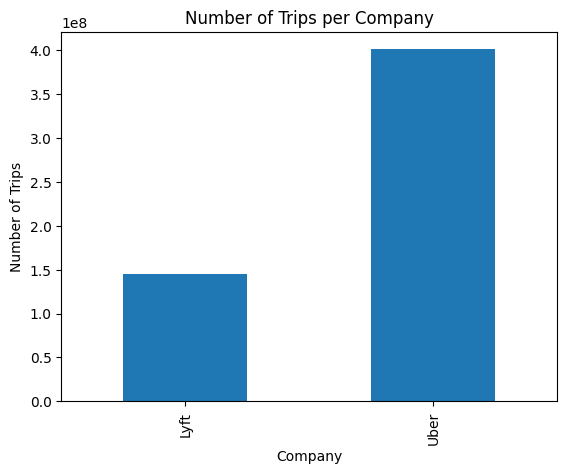

In [16]:
company_trips = analysis_cleaned.groupBy("company").count().toPandas()

company_trips.plot(kind="bar", x="company", y="count", legend=False)
plt.title("Number of Trips per Company")
plt.xlabel("Company")
plt.ylabel("Number of Trips")
plt.show()

##Number of trips per month

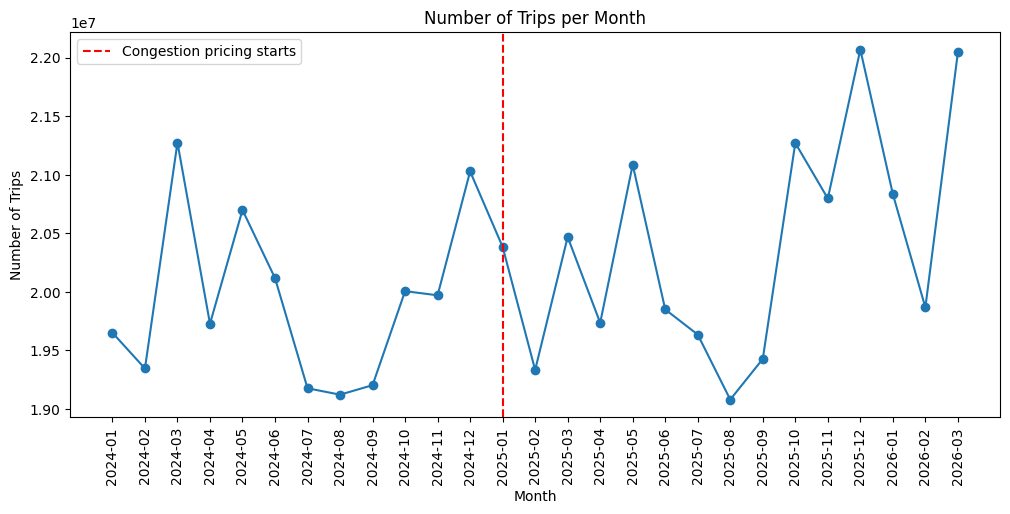

In [17]:
monthly_trips = analysis_cleaned.groupBy("pickup_month").count().orderBy("pickup_month").toPandas()

plt.figure(figsize=(12, 5))
plt.plot(monthly_trips["pickup_month"], monthly_trips["count"], marker="o")
plt.axvline("2025-01", color="red", linestyle="--", label="Congestion pricing starts")
plt.title("Number of Trips per Month")
plt.xlabel("Month")
plt.ylabel("Number of Trips")
plt.xticks(rotation=90)
plt.legend()
plt.show()

##Busiest hours

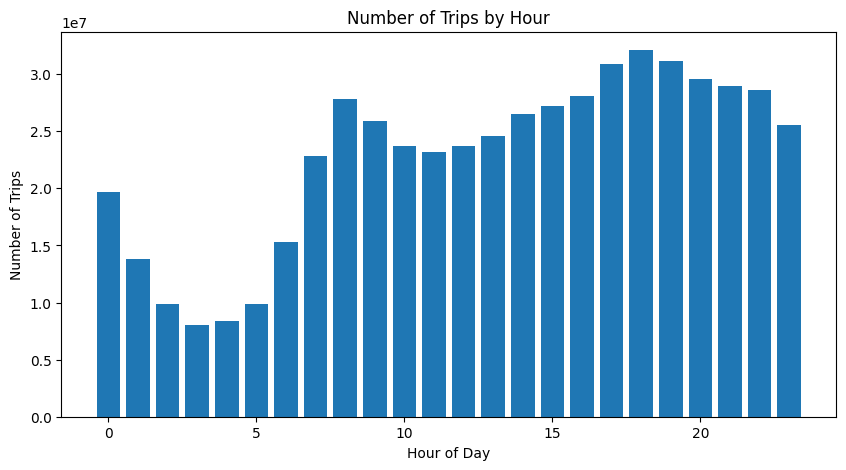

In [18]:
busy_hours = analysis_cleaned.groupBy("pickup_hour").count().orderBy("pickup_hour").toPandas()

plt.figure(figsize=(10, 5))
plt.bar(busy_hours["pickup_hour"], busy_hours["count"])
plt.title("Number of Trips by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.show()

##Number of trips by day of the week

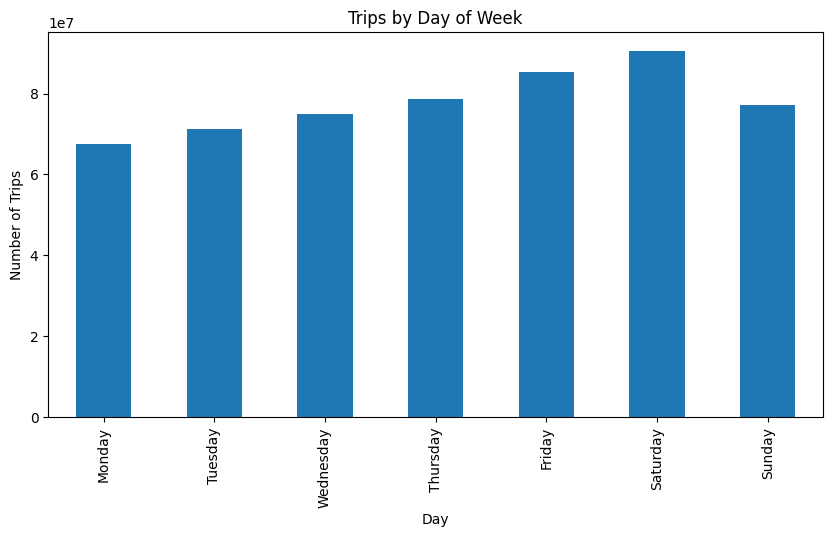

In [19]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_trips = analysis_cleaned.groupBy("pickup_day").count().toPandas().set_index("pickup_day").loc[days]

daily_trips.plot(kind="bar", legend=False, figsize=(10, 5))
plt.title("Trips by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Trips")
plt.show()

##Number of trips by pickup borough

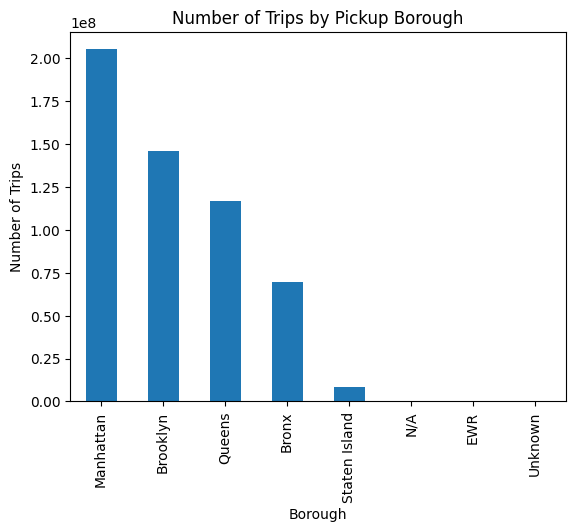

In [20]:
zones = spark.read.csv("/content/data/taxi_zone_lookup.csv", header=True, inferSchema=True)

borough = (analysis_cleaned.join(zones, clean.PULocationID == zones.LocationID)
                .groupBy("Borough").count()
                .orderBy(F.desc("count"))
                .toPandas())

borough.plot(kind="bar", x="Borough", y="count", legend=False)
plt.title("Number of Trips by Pickup Borough")
plt.ylabel("Number of Trips")
plt.show()

##Average fare and driver pay per company

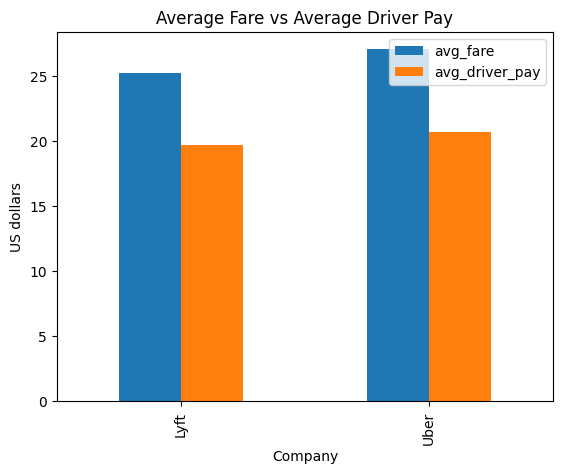

In [21]:
pay = analysis_cleaned.groupBy("company").agg(
    F.avg("base_passenger_fare").alias("avg_fare"),
    F.avg("driver_pay").alias("avg_driver_pay"),
).toPandas()

pay.plot(kind="bar", x="company", y=["avg_fare", "avg_driver_pay"])
plt.title("Average Fare vs Average Driver Pay")
plt.xlabel("Company")
plt.ylabel("US dollars")
plt.show()

##Distributions (0.1% sample)

In [22]:
sample = analysis_cleaned.sample(fraction=0.001, seed=42).toPandas()
print(f"Sample size: {len(sample):,} trips")

Sample size: 545,781 trips


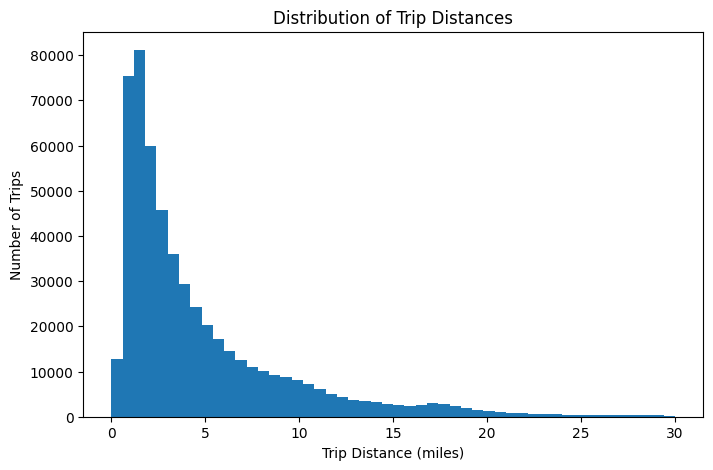

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(sample["trip_miles"], bins=50, range=(0, 30))
plt.title("Distribution of Trip Distances")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Number of Trips")
plt.show()

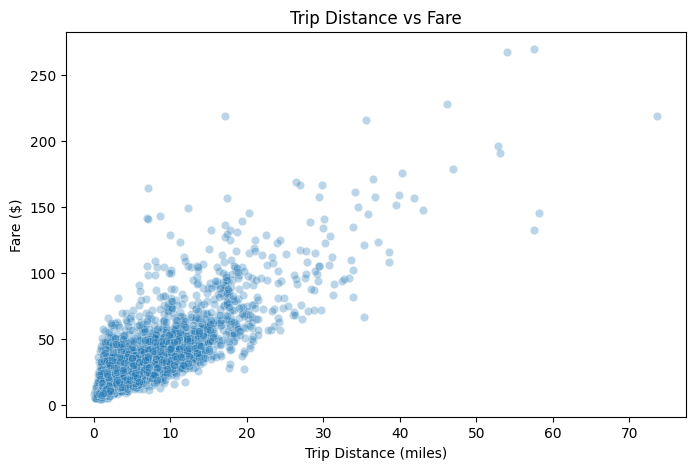

In [24]:
small = sample.sample(5000, random_state=42)

plt.figure(figsize=(8, 5))
sns.scatterplot(x="trip_miles", y="base_passenger_fare", data=small, alpha=0.3)
plt.title("Trip Distance vs Fare")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Fare ($)")
plt.show()

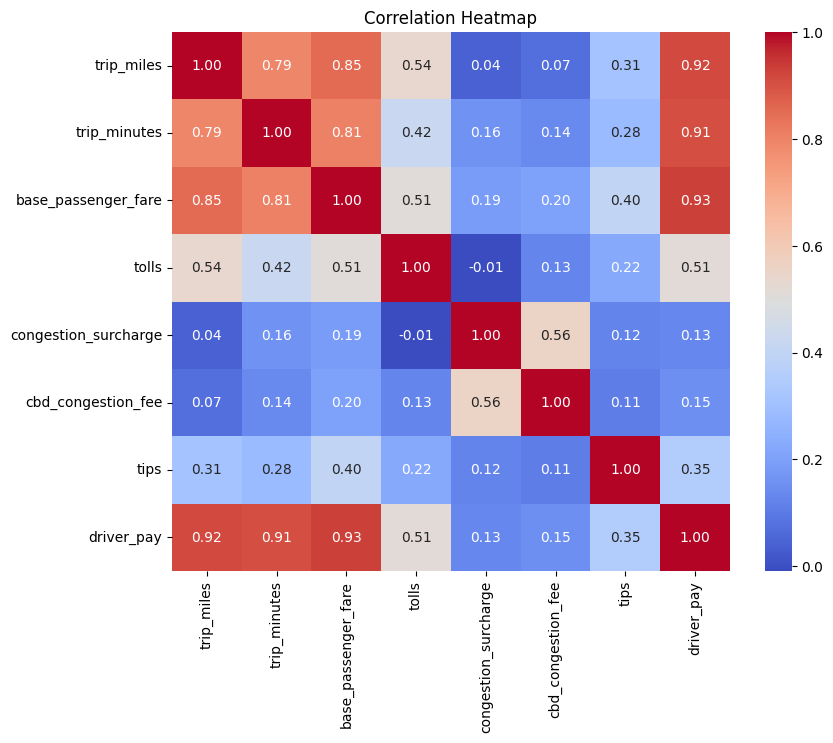

In [25]:
corr_cols = ["trip_miles", "trip_minutes", "base_passenger_fare", "tolls",
             "congestion_surcharge", "cbd_congestion_fee", "tips", "driver_pay"]

plt.figure(figsize=(9, 7))
sns.heatmap(sample[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()